# Dataset: Heart Disease UCI

[Kaggle dataset](https://www.kaggle.com/datasets/navneetkaurbrarr/hospital-patients)

In [39]:

file_id = '1cvfvS9Si268mhzpehXTYseOwsxRemV85'

url = f'https://drive.google.com/uc?id={file_id}'


## Import libraries

In [96]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## Dataset

In [41]:
df = pd.read_csv(url)

## Dataset Analysis

In [42]:
print('Heart Disease UCI Dataset')
print('=' * 50)

print(f"Dataset shape: {df.shape}\n")
print(f"{df.info()}\n")

print(df.describe(), '\n')
print(f"Missing value\n{df.isna().sum()}")

Heart Disease UCI Dataset
Dataset shape: (918, 11)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       918 non-null    int64  
 1   sex       918 non-null    object 
 2   cp        918 non-null    object 
 3   trestbps  918 non-null    float64
 4   chol      918 non-null    float64
 5   fbs       918 non-null    bool   
 6   restecg   918 non-null    object 
 7   thalch    918 non-null    float64
 8   exang     918 non-null    bool   
 9   oldpeak   918 non-null    float64
 10  num       918 non-null    int64  
dtypes: bool(2), float64(4), int64(2), object(3)
memory usage: 66.5+ KB
None

              age    trestbps        chol      thalch    oldpeak         num
count  918.000000  918.000000  918.000000  918.000000  918.00000  918.000000
mean    53.510893  132.141612  199.862745  137.689542    0.85512    0.995643
std      9.432617   17.9247

## Меры центра

In [43]:
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,num
0,63,Male,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,0
1,67,Male,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,2
2,67,Male,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,1
3,37,Male,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,0
4,41,Female,typical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,0


In [48]:
age_mean = (df
            .query('`num` > 0')
            .groupby('sex')
            ['age']
            .mean().round()
            )

display(age_mean)
print("Средний возраст мужчин и женщин имеющих сердечно-сосудистые заболевания равно 56 лет")

,age
sex,
Female,56.0
Male,56.0


In [52]:
trestbps_median = (df
               .query('`num` > 0')
               ['trestbps']
               .median()
               )

display(trestbps_median)
print('Медианное значение давления среди пациентов с сердечно-сосудистыми заболеваниями равно 130')

130.0

Медианное значение давления среди пациентов с сердечно-сосудистыми заболеваниями равно 130


In [53]:
thalch_mode = (df
               .query('`num` > 0')
               ['thalch']
               .mode()
               )
display(thalch_mode)
print('Модное значение максимальной частоты сердечных сокращений среди пациентов с сердечно-сосудистыми заболеваниями равно 140')

,thalch
0,140.0


Модное значение максимальной частоты сердечных сокращений среди пациентов с сердечно-сосудистыми заболеваниями равно 140


## Меры разброса

In [71]:
age_std = (df
            ['age']
            .std()
            )

print(f"Разброс возраста +- в {age_std:.0f} лет")

Разброс возраста +- в 9 лет


In [77]:
thalch_var = (df
            ['thalch']
            .var()
            )

print(f"Разброс максимальной частоты сердечных сокращений по дисперсии равно {thalch_var:.0f}")

Разброс максимальной частоты сердечных сокращений по дисперсии равно 633


In [88]:
IQR_trestbps = (df['trestbps'].quantile(0.75) - df['trestbps'].quantile(0.25))
print(f"50 % пациентов имеют давление в диапазоне {IQR_trestbps:.0f} мм")


50 % пациентов имеют давление в диапазоне 20 мм


## Skew, kurtosis

In [95]:
num_cols = ['age', 'trestbps', 'chol', 'thalch', 'oldpeak']

shape = pd.DataFrame({
    'skew': df[num_cols].skew(),
    'kurtosis': df[num_cols].kurtosis()
})
print(shape.round(2))
print()
print("age имеет левостороннюю асимметрию 0.2 более длинный хвост слева, oldpeak напротив имеет правостороннюю асимметрию 1.13 более длинный хвост справа, а также имеет положительный эксцесс 1.46 что означает, что у него более острая вершина (пик), чем у нормального распределения.")
print("большинство признаков перекошены влево, есть выбросы в сторону высоких значений")

          skew  kurtosis
age      -0.20     -0.39
trestbps  0.68      0.91
chol     -0.64      0.17
thalch   -0.24     -0.32
oldpeak   1.13      1.46

age имеет левостороннюю асимметрию 0.2 более длинный хвост слева, oldpeak напротив имеет правостороннюю асимметрию 1.13 более длинный хвост справа, а также имеет положительный эксцесс 1.46 что означает, что у него более острая вершина (пик), чем у нормального распределения.
большинство признаков перекошены вправо, есть выбросы в сторону высоких значений


## Корреляционная матрица, heatmap

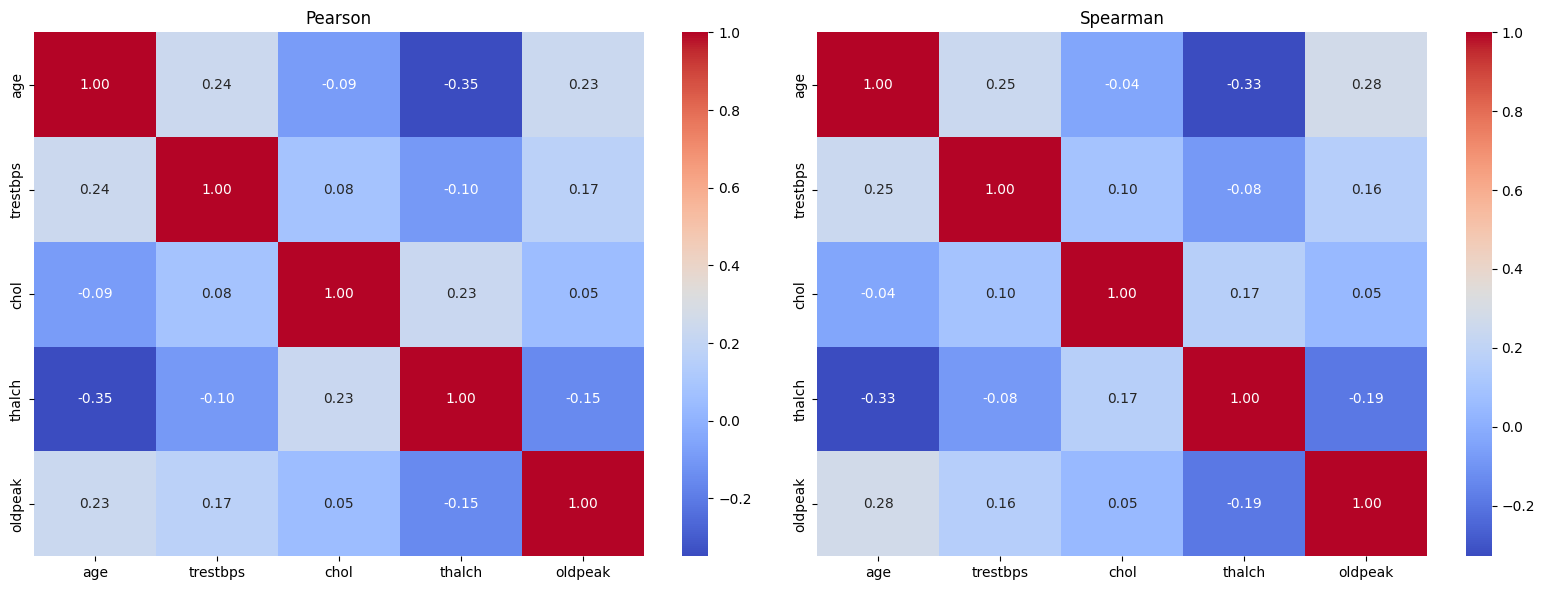

In [97]:
pearson = df[num_cols].corr(method='pearson')

spearman = df[num_cols].corr(method='spearman')

# Heatmap
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(pearson, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0])
axes[0].set_title('Pearson')

sns.heatmap(spearman, annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('Spearman')

plt.tight_layout()
plt.show()

In [102]:
print('''Heatmap показывает слабую корреляцию между колонками, топ 3 связанных пары здесь:
 Age - trestbps (чем старше, тем выше давление),
 age - oldpeak (чем старше, тем выше ST-депрессия),
 age - thalch (чем старше, тем ниже макс.пульс)''')


Heatmap показывает слабую корреляцию между колонками, топ 3 связанных пары здесь: 
 Age - trestbps (чем старше, тем выше давление), 
 age - oldpeak (чем старше, тем выше ST-депрессия), 
 age - thalch (чем старше, тем ниже макс.пульс)


## Статистический тест

In [112]:
print("""
H_0: средний возраст не различается между мужчинами и женщинами.
H_1: средний возраст различается.\n""")

from scipy import stats

male_age = df[df['sex'] == 'Male']['age']
female_age = df[df['sex'] == 'Female']['age']

t_stat, p_value = stats.ttest_ind(male_age, female_age)
print(f't-statistic: {t_stat:.3f}')
print(f'p-value: {p_value:.4f}')

print("""\np-value = 0.09 > 0.05, не отвергаем H_0.
Статистически значимого различия в возрасте между мужчинами и женщинами нет""")


H_0: средний возраст не различается между мужчинами и женщинами.
H_1: средний возраст различается.

t-statistic: 1.690
p-value: 0.0914

p-value = 0.09 > 0.05, не отвергаем H_0.
Статистически значимого различия в возрасте между мужчинами и женщинами нет


## Вывод

Возраст ключевой фактор. С ним связаны давление, пульс и ST-депрессия.

Средний возраст не различается между мужчинами и женщинами.

Большинство признаков перекошены влево, также имеют более острую вершину (пик), чем у нормального распределения.

Корреляции слабые, линейные модели могут показать невысокую точность, имеет смысл использовать нелинейные методы (Random Forest, Градиентный бустинг и т.д).